In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("mushroom_problem_identification.csv")

df.head()

,Cap color,Stalk shape,Solitary,Edible
0,Brown,Tapering,Yes,1
1,Brown,Enlarging,Yes,1
2,Brown,Tapering,No,0
3,Brown,Enlarging,No,0
4,Brown,Tapering,Yes,1


In [3]:
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (10, 4)
Columns: ['Cap color', 'Stalk shape', 'Solitary', 'Edible']
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Cap color    10 non-null     str  
 1   Stalk shape  10 non-null     str  
 2   Solitary     10 non-null     str  
 3   Edible       10 non-null     int64
dtypes: int64(1), str(3)
memory usage: 606.0 bytes

Missing values:
Cap color      0
Stalk shape    0
Solitary       0
Edible         0
dtype: int64

Duplicate rows: 3


In [4]:
features = ["Cap color", "Stalk shape", "Solitary"]
target = "Edible"

X = df[features]
y = df[target]

print("Features:", features)
print("Target:", target)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Features: ['Cap color', 'Stalk shape', 'Solitary']
Target: Edible

Target distribution:
Edible
0    5
1    5
Name: count, dtype: int64


In [5]:
for feature in features:
    print("\n", feature)
    print(pd.crosstab(df[feature], df[target]))


 Cap color
Edible     0  1
Cap color      
Brown      3  4
Red        2  1

 Stalk shape
Edible       0  1
Stalk shape      
Enlarging    3  2
Tapering     2  3

 Solitary
Edible    0  1
Solitary      
No        4  1
Yes       1  4


## Entropy and Gini Impurity

Entropy and Gini Impurity measure the impurity of a dataset. A pure dataset contains observations from only one class and has zero impurity.

**Entropy:**

H(S) = −Σ pᵢ log₂(pᵢ)

**Gini Impurity:**

Gini(S) = 1 − Σ pᵢ²

Here, pᵢ is the proportion of observations belonging to class i. I implement both formulas using NumPy and calculate the impurity of the complete dataset.

In [6]:
def entropy(labels):
    counts = np.unique(labels, return_counts=True)[1]
    probabilities = counts / len(labels)

    return -np.sum(probabilities * np.log2(probabilities))

In [7]:
print("Dataset Entropy:", entropy(y))

Dataset Entropy: 1.0


In [8]:
def gini(labels):
    counts = np.unique(labels, return_counts=True)[1]
    probabilities = counts / len(labels)

    return 1 - np.sum(probabilities ** 2)

In [9]:
print("Dataset Gini Impurity:", gini(y))

Dataset Gini Impurity: 0.5


## Evaluating Feature Splits

A feature split divides the dataset into smaller groups based on its values. I calculate the weighted Entropy and weighted Gini Impurity for each feature.

**Weighted Impurity:**

Weighted Impurity = Σ (Nᵢ / N) × Impurity(Sᵢ)

Here, Nᵢ is the number of observations in a subset, and N is the total number of observations. Weighting ensures that larger subsets contribute more to the final impurity.

In [10]:
def split_impurities(data, feature, target):
    weighted_entropy = 0
    weighted_gini = 0

    for value in data[feature].unique():
        subset = data[data[feature] == value]
        weight = len(subset) / len(data)

        weighted_entropy += weight * entropy(subset[target])
        weighted_gini += weight * gini(subset[target])

    return weighted_entropy, weighted_gini

## Information Gain and Gini Reduction

Information Gain measures the reduction in Entropy after splitting the dataset. Gini Reduction measures the reduction in Gini Impurity.

**Information Gain:**

Information Gain = Parent Entropy − Weighted Entropy

**Gini Reduction:**

Gini Reduction = Parent Gini − Weighted Gini

I calculate both measures for every feature and plot the results. The feature with the highest Information Gain is selected as the root feature for the Entropy-based tree.

In [11]:
parent_entropy = entropy(y)
parent_gini = gini(y)

results = []

for feature in features:
    weighted_entropy, weighted_gini = split_impurities(
        df, feature, target
    )

    results.append({
        "Feature": feature,
        "Weighted Entropy": weighted_entropy,
        "Information Gain": parent_entropy - weighted_entropy,
        "Weighted Gini": weighted_gini,
        "Gini Reduction": parent_gini - weighted_gini
    })

scores = pd.DataFrame(results)

display(scores.round(4))

,Feature,Weighted Entropy,Information Gain,Weighted Gini,Gini Reduction
0,Cap color,0.9651,0.0349,0.4762,0.0238
1,Stalk shape,0.9710,0.0290,0.4800,0.0200
2,Solitary,0.7219,0.2781,0.3200,0.1800


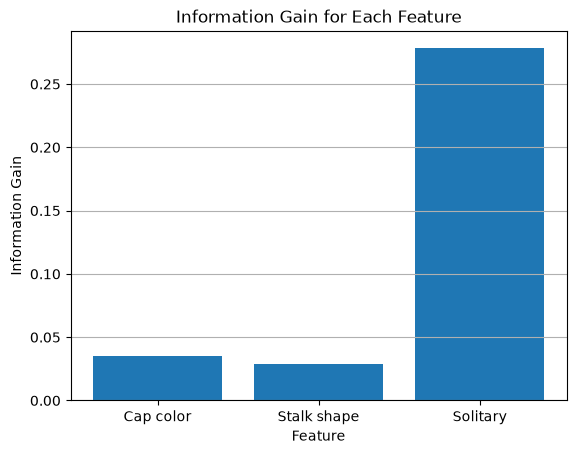

In [12]:
plt.bar(scores["Feature"], scores["Information Gain"])
plt.xlabel("Feature")
plt.ylabel("Information Gain")
plt.title("Information Gain for Each Feature")
plt.grid(axis="y")
plt.show()

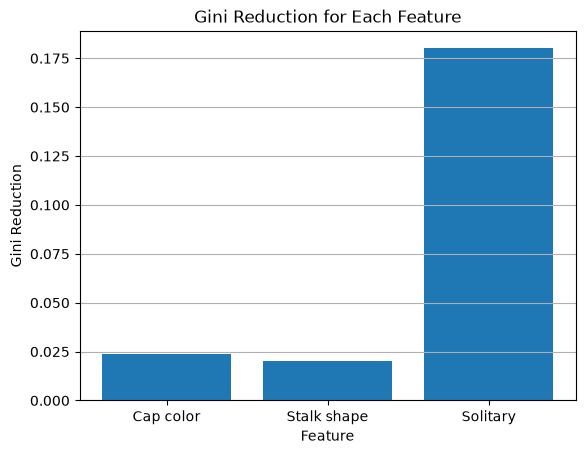

In [13]:
plt.bar(scores["Feature"], scores["Gini Reduction"])
plt.xlabel("Feature")
plt.ylabel("Gini Reduction")
plt.title("Gini Reduction for Each Feature")
plt.grid(axis="y")
plt.show()

## Selecting the Root Feature

The root is the first decision node of a Decision Tree. I select the feature with the highest Information Gain and examine the class distribution, Entropy, and Gini Impurity of its subsets.

In this dataset, `Solitary` has the highest Information Gain and is selected as the root feature.

In [14]:
best_feature = scores.loc[
    scores["Information Gain"].idxmax(), "Feature"
]
## 6. Selecting the Root Feature

The root is the first decision node of a Decision Tree. I select the feature with the highest Information Gain and examine the class distribution, Entropy, and Gini Impurity of its subsets.

In this dataset, `Solitary` has the highest Information Gain and is selected as the root feature.
print("Information Gain:", scores["Information Gain"].max())

Best root feature: Solitary
Information Gain: 0.2780719051126377


In [15]:
for value in df[best_feature].unique():
    subset = df[df[best_feature] == value]

    print("\nSolitary =", value)
    print("Rows:", len(subset))
    print("Class counts:")
    print(subset[target].value_counts().sort_index())
    print("Entropy:", round(entropy(subset[target]), 4))
    print("Gini:", round(gini(subset[target]), 4))


Solitary = Yes
Rows: 5
Class counts:
Edible
0    1
1    4
Name: count, dtype: int64
Entropy: 0.7219
Gini: 0.32

Solitary = No
Rows: 5
Class counts:
Edible
0    4
1    1
Name: count, dtype: int64
Entropy: 0.7219
Gini: 0.32


## Building the Decision Tree Using Information Gain

I build the tree recursively using Information Gain. At each step, the feature with the highest Information Gain is selected, and the data is divided according to its values.

The process stops when a subset contains only one class or when no features remain. The resulting tree is represented using nested Python dictionaries.

In [16]:
def information_gain(data, feature, target):
    weighted_entropy, weighted_gini = split_impurities(
        data, feature, target
    )

    return entropy(data[target]) - weighted_entropy

In [17]:
def build_tree(data, features, target):
    labels = data[target]

    if labels.nunique() == 1:
        return int(labels.iloc[0])

    if len(features) == 0:
        return int(labels.mode()[0])

    gains = [
        information_gain(data, feature, target)
        for feature in features
    ]

    best_feature = features[np.argmax(gains)]

    tree = {best_feature: {}}

    remaining_features = [
        feature for feature in features
        if feature != best_feature
    ]

    for value in data[best_feature].unique():
        subset = data[data[best_feature] == value]

        tree[best_feature][value] = build_tree(
            subset, remaining_features, target
        )

    return tree

In [18]:
tree = build_tree(df, features, target)

print(tree)

{'Solitary': {'Yes': {'Cap color': {'Brown': 1, 'Red': 0}}, 'No': {'Cap color': {'Brown': 0, 'Red': {'Stalk shape': {'Enlarging': 0, 'Tapering': 1}}}}}}


In [19]:
def predict(tree, sample, default=0):
    if not isinstance(tree, dict):
        return tree

    feature = next(iter(tree))
    value = sample[feature]

    if value not in tree[feature]:
        return default

    return predict(tree[feature][value], sample, default)

In [20]:
y_actual = df[target].values
y_pred = np.array([predict(tree, row) for _, row in df.iterrows()])

print("Actual values:", y_actual)
print("Predicted values:", y_pred)

Actual values: [1 1 0 0 1 0 0 1 1 0]
Predicted values: [1 1 0 0 1 0 0 1 1 0]


In [21]:
correct = np.sum(y_actual == y_pred)
accuracy = correct / len(y_actual) * 100

print("Correct predictions:", correct)
print("Total predictions:", len(y_actual))
print("Accuracy:", accuracy, "%")

Correct predictions: 10
Total predictions: 10
Accuracy: 100.0 %


In [22]:
TP = np.sum((y_actual == 1) & (y_pred == 1))
TN = np.sum((y_actual == 0) & (y_pred == 0))
FP = np.sum((y_actual == 0) & (y_pred == 1))
FN = np.sum((y_actual == 1) & (y_pred == 0))

conf_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[5 0]
 [0 5]]


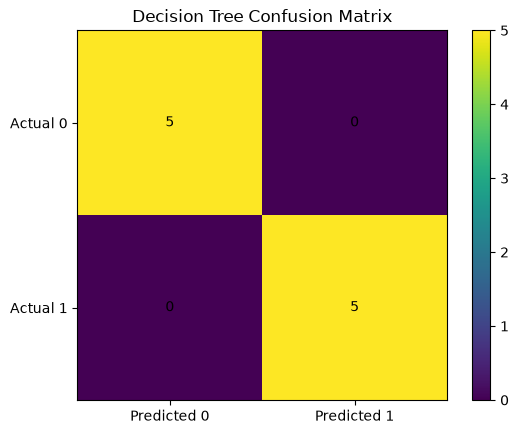

In [23]:
plt.imshow(conf_matrix)
plt.colorbar()

plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, conf_matrix[i, j],
                 ha="center", va="center")

plt.title("Decision Tree Confusion Matrix")
plt.show()

## Building the Decision Tree Using Gini Reduction

I implement a second Decision Tree that selects features using Gini Reduction instead of Information Gain. The tree-building process is otherwise similar to the Entropy-based method.

I compare the resulting tree and its training accuracy with the Entropy-based tree.

In [24]:
def gini_reduction(data, feature, target):
    _, weighted_gini = split_impurities(data, feature, target)

    return gini(data[target]) - weighted_gini

In [25]:
def build_gini_tree(data, features, target):
    labels = data[target]

    if labels.nunique() == 1:
        return int(labels.iloc[0])

    if len(features) == 0:
        return int(labels.mode()[0])

    reductions = [
        gini_reduction(data, feature, target)
        for feature in features
    ]

    best_feature = features[np.argmax(reductions)]

    tree = {best_feature: {}}

    remaining_features = [
        feature for feature in features
        if feature != best_feature
    ]

    for value in data[best_feature].unique():
        subset = data[data[best_feature] == value]

        tree[best_feature][value] = build_gini_tree(
            subset, remaining_features, target
        )

    return tree

In [26]:
gini_tree = build_gini_tree(df, features, target)

print("Gini-based Decision Tree:")
print(gini_tree)

Gini-based Decision Tree:
{'Solitary': {'Yes': {'Cap color': {'Brown': 1, 'Red': 0}}, 'No': {'Cap color': {'Brown': 0, 'Red': {'Stalk shape': {'Enlarging': 0, 'Tapering': 1}}}}}}


In [27]:
y_pred_gini = np.array([
    predict(gini_tree, row)
    for _, row in df.iterrows()
])

accuracy_entropy = np.mean(y_actual == y_pred) * 100
accuracy_gini = np.mean(y_actual == y_pred_gini) * 100

print("Entropy-based accuracy:", accuracy_entropy, "%")
print("Gini-based accuracy:", accuracy_gini, "%")

Entropy-based accuracy: 100.0 %
Gini-based accuracy: 100.0 %


In [28]:
df_eval = df.drop_duplicates().reset_index(drop=True)

np.random.seed(42)
indices = np.random.permutation(len(df_eval))

split = int(0.7 * len(df_eval))

train_df = df_eval.iloc[indices[:split]]
test_df = df_eval.iloc[indices[split:]]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 4
Testing rows: 3


In [29]:
tree_test = build_tree(train_df, features, target)

print("Training tree:")
print(tree_test)

Training tree:
{'Solitary': {'Yes': 1, 'No': 0}}


In [30]:
train_actual = train_df[target].values
test_actual = test_df[target].values

train_pred = np.array([
    predict(tree_test, row) for _, row in train_df.iterrows()
])

test_pred = np.array([
    predict(tree_test, row) for _, row in test_df.iterrows()
])

train_accuracy = np.mean(train_actual == train_pred) * 100
test_accuracy = np.mean(test_actual == test_pred) * 100

print("Training accuracy:", train_accuracy, "%")
print("Testing accuracy:", test_accuracy, "%")

Training accuracy: 100.0 %
Testing accuracy: 33.33333333333333 %


In [31]:
def build_tree_depth(data, features, target, max_depth, depth=0):
    labels = data[target]

    if labels.nunique() == 1:
        return int(labels.iloc[0])

    if depth >= max_depth or len(features) == 0:
        return int(labels.mode()[0])

    gains = [
        information_gain(data, feature, target)
        for feature in features
    ]

    best_feature = features[np.argmax(gains)]
    tree = {best_feature: {}}

    remaining_features = [
        feature for feature in features
        if feature != best_feature
    ]

    for value in data[best_feature].unique():
        subset = data[data[best_feature] == value]

        tree[best_feature][value] = build_tree_depth(
            subset, remaining_features, target,
            max_depth, depth + 1
        )

    return tree

In [32]:
depths = [1, 2, 3]
results = []

default_class = int(train_df[target].mode()[0])

for depth in depths:
    tree_d = build_tree_depth(
        train_df, features, target, max_depth=depth
    )

    train_pred_d = np.array([
        predict(tree_d, row, default_class)
        for _, row in train_df.iterrows()
    ])

    test_pred_d = np.array([
        predict(tree_d, row, default_class)
        for _, row in test_df.iterrows()
    ])

    train_acc = np.mean(
        train_df[target].values == train_pred_d
    ) * 100

    test_acc = np.mean(
        test_df[target].values == test_pred_d
    ) * 100

    results.append({
        "Max Depth": depth,
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc
    })

depth_results = pd.DataFrame(results)
display(depth_results)

,Max Depth,Training Accuracy,Testing Accuracy
0,1,100.0,33.333333
1,2,100.0,33.333333
2,3,100.0,33.333333


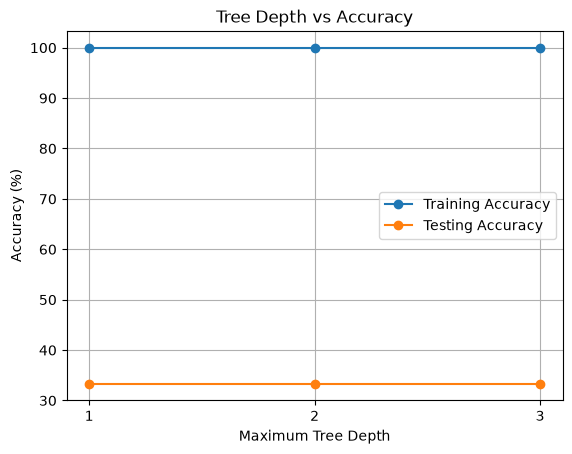

In [33]:
plt.plot(
    depth_results["Max Depth"],
    depth_results["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["Max Depth"],
    depth_results["Testing Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy (%)")
plt.title("Tree Depth vs Accuracy")
plt.xticks(depths)
plt.legend()
plt.grid()
plt.show()